In [7]:
!pip -q install numpy matplotlib scikit-learn pytest ipywidgets

!mkdir -p src tests outputs
!touch src/__init__.py

In [8]:
%%writefile src/neural_network.py
import numpy as np


class NeuralNetwork:
    """64 -> 32 -> 10 MLP implemented with NumPy only."""

    def __init__(self, input_size=64, hidden_size=32,
                 output_size=10, seed=42):

        rng = np.random.default_rng(seed)

        self.W1 = rng.normal(
            0, 1 / np.sqrt(input_size),
            (input_size, hidden_size)
        )
        self.b1 = np.zeros((1, hidden_size))

        self.W2 = rng.normal(
            0, 1 / np.sqrt(hidden_size),
            (hidden_size, output_size)
        )
        self.b2 = np.zeros((1, output_size))

    def forward(self, X):
        hidden = np.tanh(X @ self.W1 + self.b1)

        logits = hidden @ self.W2 + self.b2
        exp_logits = np.exp(
            logits - logits.max(axis=1, keepdims=True)
        )

        probs = exp_logits / exp_logits.sum(
            axis=1, keepdims=True
        )

        return hidden, probs

    def loss_and_grads(self, X, y):
        hidden, probs = self.forward(X)
        n = len(y)

        loss = -np.log(
            np.clip(
                probs[np.arange(n), y], 1e-12, 1
            )
        ).mean()

        # Backpropagation
        dlogits = probs.copy()
        dlogits[np.arange(n), y] -= 1
        dlogits /= n

        dW2 = hidden.T @ dlogits
        db2 = dlogits.sum(axis=0, keepdims=True)

        dhidden = (
            dlogits @ self.W2.T
        ) * (1 - hidden ** 2)

        dW1 = X.T @ dhidden
        db1 = dhidden.sum(axis=0, keepdims=True)

        return loss, {
            "W1": dW1,
            "b1": db1,
            "W2": dW2,
            "b2": db2
        }

    def predict_proba(self, X):
        return self.forward(X)[1]

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def evaluate(self, X, y):
        probs = self.predict_proba(X)

        loss = -np.log(
            np.clip(
                probs[np.arange(len(y)), y],
                1e-12, 1
            )
        ).mean()

        accuracy = np.mean(
            probs.argmax(axis=1) == y
        )

        return float(loss), float(accuracy)

    def fit(self, X, y, X_val, y_val,
            epochs=150, batch_size=64,
            lr=0.35, seed=42):

        rng = np.random.default_rng(seed)

        history = {
            "train_loss": [],
            "val_loss": [],
            "train_acc": [],
            "val_acc": []
        }

        for _ in range(epochs):
            indices = rng.permutation(len(X))

            for start in range(
                0, len(X), batch_size
            ):
                batch = indices[
                    start:start + batch_size
                ]

                _, grads = self.loss_and_grads(
                    X[batch], y[batch]
                )

                # Gradient Descent
                for name, grad in grads.items():
                    setattr(
                        self,
                        name,
                        getattr(self, name) - lr * grad
                    )

            for label, a, b in (
                ("train", X, y),
                ("val", X_val, y_val)
            ):
                loss, acc = self.evaluate(a, b)

                history[f"{label}_loss"].append(loss)
                history[f"{label}_acc"].append(acc)

        return history

Writing src/neural_network.py


In [9]:
%%writefile src/train.py
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

from src.neural_network import NeuralNetwork


def load_data():
    digits = load_digits()

    X = digits.data.astype(np.float64) / 16.0
    y = digits.target.astype(int)

    X_partial, X_test, y_partial, y_test = (
        train_test_split(
            X, y,
            test_size=0.15,
            stratify=y,
            random_state=42
        )
    )

    X_train, X_val, y_train, y_val = (
        train_test_split(
            X_partial,
            y_partial,
            test_size=0.15 / 0.85,
            stratify=y_partial,
            random_state=42
        )
    )

    return (
        X_train, X_val, X_test,
        y_train, y_val, y_test
    )


def main():
    out = Path("outputs")
    out.mkdir(exist_ok=True)

    (
        X_train, X_val, X_test,
        y_train, y_val, y_test
    ) = load_data()

    model = NeuralNetwork(seed=42)

    history = model.fit(
        X_train, y_train,
        X_val, y_val
    )

    test_loss, test_acc = model.evaluate(
        X_test, y_test
    )

    # Save trained model
    np.savez_compressed(
        out / "model.npz",
        W1=model.W1,
        b1=model.b1,
        W2=model.W2,
        b2=model.b2
    )

    # Save metrics
    metrics = {
        "train_samples": len(X_train),
        "validation_samples": len(X_val),
        "test_samples": len(X_test),
        "test_loss": test_loss,
        "test_accuracy": test_acc
    }

    (out / "metrics.json").write_text(
        json.dumps(metrics, indent=2)
    )

    # Training curves
    fig, axes = plt.subplots(
        1, 2, figsize=(11, 4)
    )

    for name in ("train", "val"):
        axes[0].plot(
            history[f"{name}_loss"],
            label=name
        )
        axes[1].plot(
            history[f"{name}_acc"],
            label=name
        )

    axes[0].set(
        title="Cross-entropy loss",
        xlabel="Epoch"
    )

    axes[1].set(
        title="Accuracy",
        xlabel="Epoch",
        ylim=(0, 1)
    )

    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.2)

    fig.tight_layout()
    fig.savefig(
        out / "training_curves.png",
        dpi=160
    )
    plt.close(fig)

    # Visualize the 32 hidden neurons
    fig, axes = plt.subplots(
        4, 8, figsize=(12, 6)
    )

    scale = np.abs(model.W1).max()

    for k, ax in enumerate(axes.flat):
        ax.imshow(
            model.W1[:, k].reshape(8, 8),
            cmap="coolwarm",
            vmin=-scale,
            vmax=scale
        )
        ax.set_title(
            f"Neuron {k}", fontsize=8
        )
        ax.axis("off")

    fig.suptitle(
        "Learned input weights of 32 hidden neurons"
    )
    fig.tight_layout()

    fig.savefig(
        out / "neuron_weights.png",
        dpi=160
    )
    plt.close(fig)

    print(
        f"Train: {len(X_train)} | "
        f"Validation: {len(X_val)} | "
        f"Test: {len(X_test)}"
    )

    print(
        f"Test accuracy: {test_acc:.2%} | "
        f"Test loss: {test_loss:.4f}"
    )

    print("Results saved in outputs/")


if __name__ == "__main__":
    main()

Writing src/train.py


In [10]:
%%writefile tests/test_neural_network.py
import numpy as np

from src.neural_network import NeuralNetwork


def test_probabilities():
    model = NeuralNetwork(
        input_size=4,
        hidden_size=5,
        output_size=3
    )

    X = np.ones((6, 4))
    p = model.predict_proba(X)

    assert p.shape == (6, 3)

    np.testing.assert_allclose(
        p.sum(axis=1),
        1,
        atol=1e-12
    )


def test_backpropagation_against_finite_differences():
    model = NeuralNetwork(
        input_size=4,
        hidden_size=3,
        output_size=2
    )

    X = np.array([
        [0.2, 0.8, 0.1, 0.3],
        [0.5, 0.0, 0.9, 0.1]
    ])

    y = np.array([0, 1])

    _, grads = model.loss_and_grads(X, y)

    epsilon = 1e-5

    for name in ("W1", "b1", "W2", "b2"):
        param = getattr(model, name)

        for idx in np.ndindex(param.shape):
            original = param[idx]

            param[idx] = original + epsilon
            plus = model.loss_and_grads(X, y)[0]

            param[idx] = original - epsilon
            minus = model.loss_and_grads(X, y)[0]

            param[idx] = original

            numerical = (
                plus - minus
            ) / (2 * epsilon)

            np.testing.assert_allclose(
                numerical,
                grads[name][idx],
                rtol=1e-4,
                atol=1e-7
            )


def test_training_decreases_loss():
    model = NeuralNetwork(
        input_size=4,
        hidden_size=6,
        output_size=2
    )

    rng = np.random.default_rng(3)
    X = rng.uniform(size=(100, 4))

    y = (
        X[:, 0] + X[:, 1] > 1
    ).astype(int)

    before = model.evaluate(X, y)[0]

    model.fit(
        X, y, X, y,
        epochs=80,
        lr=0.4
    )

    after = model.evaluate(X, y)[0]

    assert after < before

Writing tests/test_neural_network.py


In [11]:
!python -m pytest -q tests
!python -m src.train

...                                                                      [100%]
3 passed in 0.15s
Train: 1257 | Validation: 270 | Test: 270
Test accuracy: 98.15% | Test loss: 0.0772
Results saved in outputs/


In [12]:
import numpy as np
import matplotlib.pyplot as plt

from ipywidgets import interact, IntSlider
from src.neural_network import NeuralNetwork
from src.train import load_data

_, _, X_test, _, _, y_test = load_data()

model = NeuralNetwork()

with np.load("outputs/model.npz") as weights:
    for name in ("W1", "b1", "W2", "b2"):
        setattr(model, name, weights[name].copy())


def inspect_neuron(image=0, neuron=0):
    x = X_test[image]

    hidden, probs = model.forward(
        x.reshape(1, -1)
    )

    activation = hidden[0, neuron]

    fig, axes = plt.subplots(
        1, 4, figsize=(15, 3.5)
    )

    # Input image
    axes[0].imshow(
        x.reshape(8, 8),
        cmap="gray_r"
    )
    axes[0].set_title(
        f"Input: {y_test[image]}"
    )
    axes[0].axis("off")

    # Hidden neuron activations
    axes[1].imshow(
        hidden.reshape(4, 8),
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    axes[1].scatter(
        neuron % 8,
        neuron // 8,
        s=250,
        marker="s",
        facecolors="none",
        edgecolors="lime",
        linewidths=2
    )

    axes[1].set_title(
        "32 Neuron Activations"
    )
    axes[1].axis("off")

    # Neuron weights
    weights = model.W1[:, neuron].reshape(8, 8)

    scale = np.max(np.abs(weights))

    axes[2].imshow(
        weights,
        cmap="coolwarm",
        vmin=-scale,
        vmax=scale
    )

    axes[2].set_title(
        f"Neuron {neuron}\n"
        f"Activation: {activation:.3f}"
    )
    axes[2].axis("off")

    # Output predictions
    axes[3].bar(
        range(10),
        probs[0]
    )

    axes[3].set_xticks(range(10))
    axes[3].set_ylim(0, 1)

    axes[3].set_title(
        f"Prediction: {probs.argmax()}"
    )
    axes[3].set_xlabel("Digit")
    axes[3].set_ylabel("Probability")

    plt.tight_layout()
    plt.show()
    plt.close(fig)


interact(
    inspect_neuron,

    image=IntSlider(
        min=0,
        max=len(X_test)-1,
        value=0,
        description="Image"
    ),

    neuron=IntSlider(
        min=0,
        max=31,
        value=0,
        description="Neuron"
    )
)

interactive(children=(IntSlider(value=0, description='Image', max=269), IntSlider(value=0, description='Neuron…

<function __main__.inspect_neuron(image=0, neuron=0)>

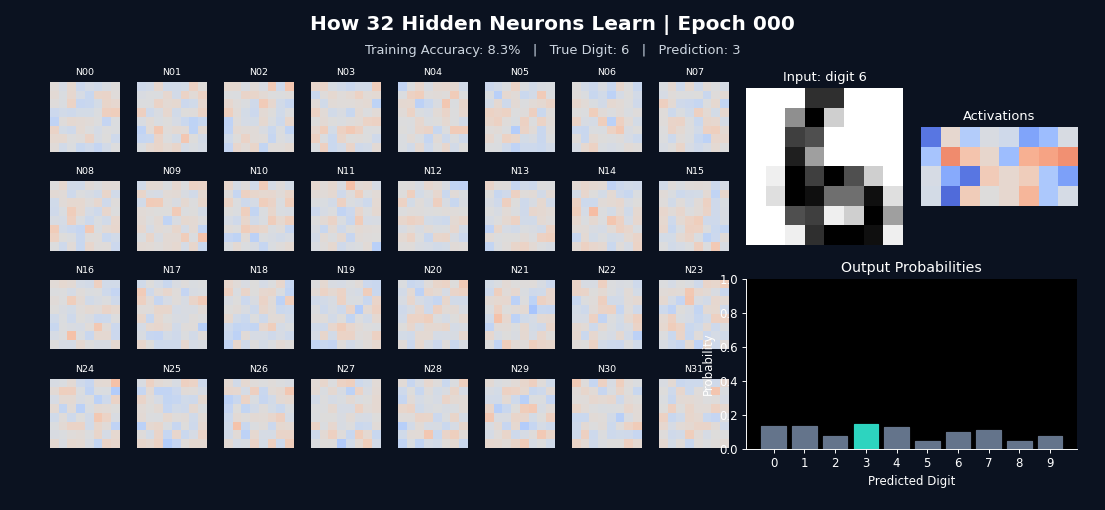

Animation created successfully.
Total frames: 31
Saved to: outputs/neuron_learning.gif


In [13]:

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display
from pathlib import Path

from src.neural_network import NeuralNetwork
from src.train import load_data


# Load dataset
X_train, X_val, X_test, y_train, y_val, y_test = load_data()

# Fresh model for recording the learning process
viz_model = NeuralNetwork(seed=42)
train_rng = np.random.default_rng(42)

sample_index = 0
sample_image = X_test[sample_index:sample_index + 1]
true_digit = int(y_test[sample_index])

snapshots = []


def record_snapshot(epoch):
    hidden, probs = viz_model.forward(sample_image)
    _, accuracy = viz_model.evaluate(X_train, y_train)

    snapshots.append({
        "epoch": epoch,
        "weights": viz_model.W1.copy(),
        "hidden": hidden[0].copy(),
        "probs": probs[0].copy(),
        "accuracy": accuracy
    })


# Train and capture every 5 epochs
record_snapshot(0)

for epoch in range(1, 151):

    permutation = train_rng.permutation(len(X_train))

    for start in range(0, len(X_train), 64):
        batch = permutation[start:start + 64]

        _, gradients = viz_model.loss_and_grads(
            X_train[batch], y_train[batch]
        )

        for name, grad in gradients.items():
            setattr(
                viz_model,
                name,
                getattr(viz_model, name) - 0.35 * grad
            )

    if epoch % 5 == 0:
        record_snapshot(epoch)


# Visualization
with plt.style.context("dark_background"):

    fig = plt.figure(
        figsize=(13, 6),
        facecolor="#0b1220"
    )

    grid = fig.add_gridspec(
        4, 12,
        left=0.045,
        right=0.975,
        top=0.84,
        bottom=0.12,
        wspace=0.25,
        hspace=0.4
    )

    scale = max(
        np.abs(s["weights"]).max()
        for s in snapshots
    )

    heatmaps = []

    # 32 learned neuron weight patterns
    for neuron in range(32):

        ax = fig.add_subplot(
            grid[neuron // 8, neuron % 8]
        )

        img = ax.imshow(
            snapshots[0]["weights"][:, neuron].reshape(8, 8),
            cmap="coolwarm",
            vmin=-scale,
            vmax=scale
        )

        ax.set_title(f"N{neuron:02d}", fontsize=8)
        ax.axis("off")

        heatmaps.append(img)

    # Input digit
    input_ax = fig.add_subplot(grid[0:2, 8:10])

    input_ax.imshow(
        sample_image.reshape(8, 8),
        cmap="gray_r",
        vmin=0,
        vmax=1
    )

    input_ax.set_title(
        f"Input: digit {true_digit}",
        fontsize=11
    )
    input_ax.axis("off")

    # Neuron activations
    hidden_ax = fig.add_subplot(grid[0:2, 10:12])

    hidden_img = hidden_ax.imshow(
        snapshots[0]["hidden"].reshape(4, 8),
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    hidden_ax.set_title("Activations", fontsize=11)
    hidden_ax.axis("off")

    # Output predictions
    pred_ax = fig.add_subplot(grid[2:4, 8:12])

    bars = pred_ax.bar(
        range(10),
        snapshots[0]["probs"],
        color="#64748b"
    )

    pred_ax.set_xticks(range(10))
    pred_ax.set_ylim(0, 1)
    pred_ax.set_title("Output Probabilities")
    pred_ax.set_xlabel("Predicted Digit")
    pred_ax.set_ylabel("Probability")

    pred_ax.spines["top"].set_visible(False)
    pred_ax.spines["right"].set_visible(False)

    heading = fig.suptitle(
        "Neuron Learning | Epoch 0",
        fontsize=17,
        weight="bold",
        y=0.97
    )

    subtitle = fig.text(
        0.5, 0.895, "",
        ha="center",
        fontsize=11,
        color="#cbd5e1"
    )

    # Update animation
    def update(frame):

        snapshot = snapshots[frame]

        for neuron, img in enumerate(heatmaps):
            img.set_data(
                snapshot["weights"][:, neuron].reshape(8, 8)
            )

        hidden_img.set_data(
            snapshot["hidden"].reshape(4, 8)
        )

        prediction = int(
            np.argmax(snapshot["probs"])
        )

        for digit, (bar, probability) in enumerate(
            zip(bars, snapshot["probs"])
        ):
            bar.set_height(float(probability))

            bar.set_color(
                "#2dd4bf"
                if digit == prediction
                else "#64748b"
            )

        heading.set_text(
            f"How 32 Hidden Neurons Learn | "
            f"Epoch {snapshot['epoch']:03d}"
        )

        subtitle.set_text(
            f"Training Accuracy: "
            f"{snapshot['accuracy']:.1%}   |   "
            f"True Digit: {true_digit}   |   "
            f"Prediction: {prediction}"
        )

        return [
            *heatmaps,
            hidden_img,
            *bars,
            heading,
            subtitle
        ]

    anim = FuncAnimation(
        fig,
        update,
        frames=len(snapshots),
        interval=160,
        blit=False,
        repeat=True
    )

    # Save GIF for GitHub README
    Path("outputs").mkdir(exist_ok=True)

    gif_path = "outputs/neuron_learning.gif"

    anim.save(
        gif_path,
        writer=PillowWriter(fps=6),
        dpi=85
    )

    plt.close(fig)

display(Image(filename=gif_path))

print("Animation created successfully.")
print(f"Total frames: {len(snapshots)}")
print(f"Saved to: {gif_path}")


In [14]:

from pathlib import Path
import json

metrics = json.loads(
    Path("outputs/metrics.json").read_text()
)

accuracy = metrics["test_accuracy"] * 100
test_size = metrics["test_samples"]

readme = f"""# Neuron Vision
### Neural Network from Scratch | Interactive Deep Learning Visualization

A fully connected neural network implemented from scratch using
**Python and NumPy**, without TensorFlow or PyTorch.

The project demonstrates how neural networks learn through
backpropagation, gradient descent, and interactive neuron visualization.

## Demo

![Neuron Learning Animation](outputs/neuron_learning.gif)

## Results

| Metric | Value |
|---|---|
| Test Accuracy | {accuracy:.2f}% |
| Test Samples | {test_size} |
| Dataset | Scikit-learn Digits |
| Architecture | 64 → 32 → 10 |
| Hidden Activation | Tanh |
| Output Activation | Softmax |
| Loss Function | Cross-Entropy |
| Optimizer | Mini-batch Gradient Descent |
| Training Epochs | 150 |

The dataset is divided into stratified training, validation,
and held-out test sets using a fixed random seed.

## Neural Network Architecture

- Input Layer: 64 neurons representing 8×8 grayscale images
- Hidden Layer: 32 neurons with Tanh activation
- Output Layer: 10 neurons with Softmax probabilities

## Features

- Neural network implemented using NumPy
- Forward propagation and backpropagation
- Analytical gradient verification using finite differences
- Interactive neuron activation inspector
- Visualization of learned neuron weights
- Animated neuron learning process
- Training and validation performance graphs
- Automated unit tests
- Reproducible experiments

## Visualizations

### Training Performance

![Training Curves](outputs/training_curves.png)

### Learned Neuron Weights

![Learned Weights](outputs/neuron_weights.png)

### Neuron Learning Animation

![Neuron Animation](outputs/neuron_learning.gif)

Each heatmap represents the input weights learned by one hidden
neuron. The activation visualization shows how those neurons
respond to a selected handwritten digit.

## Installation

```bash
pip install -r requirements.txt
```

## Run Training

```bash
python -m src.train
```

## Run Tests

```bash
python -m pytest -q tests
```

The tests validate probability normalization, gradient correctness,
and loss reduction during training.

## Interactive Google Colab Demo

Open `neuron_vision_colab.ipynb` to explore neuron activations,
weight patterns, predictions, and the animated learning process.

## Project Structure

```text
neuron-vision-from-scratch/
├── neuron_vision_colab.ipynb
├── README.md
├── requirements.txt
├── .gitignore
├── src/
│   ├── __init__.py
│   ├── neural_network.py
│   └── train.py
├── tests/
│   └── test_neural_network.py
└── outputs/
    ├── metrics.json
    ├── model.npz
    ├── training_curves.png
    ├── neuron_weights.png
    └── neuron_learning.gif
```

## Limitations

- Uses a small 8×8 handwritten-digit dataset.
- The model is a fully connected MLP, not a CNN.
- Visualized weights are learned patterns, not literal digit templates.
- Results may differ with changes to data splits or hyperparameters.

## Technologies

Python · NumPy · Scikit-learn · Matplotlib · Pytest · Google Colab
"""

Path("README.md").write_text(
    readme, encoding="utf-8"
)

Path("requirements.txt").write_text(
    "numpy>=1.24\n"
    "matplotlib>=3.7\n"
    "scikit-learn>=1.3\n"
    "pytest>=7.0\n"
    "ipywidgets>=8.0\n"
    "pillow>=9.0\n",
    encoding="utf-8"
)

Path(".gitignore").write_text(
    "__pycache__/\n"
    "*.py[cod]\n"
    ".pytest_cache/\n"
    ".ipynb_checkpoints/\n"
    ".env\n"
    ".DS_Store\n",
    encoding="utf-8"
)

print("README.md created")
print("requirements.txt created")
print(".gitignore created")
print(f"Documented test accuracy: {accuracy:.2f}%")


README.md created
requirements.txt created
.gitignore created
Documented test accuracy: 98.15%


In [15]:

from pathlib import Path
import subprocess

required_files = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "src/__init__.py",
    "src/neural_network.py",
    "src/train.py",
    "tests/test_neural_network.py",
    "outputs/metrics.json",
    "outputs/model.npz",
    "outputs/training_curves.png",
    "outputs/neuron_weights.png",
    "outputs/neuron_learning.gif",
]

missing = [
    path for path in required_files
    if not Path(path).is_file()
]

if missing:
    print("Missing files:")
    for path in missing:
        print(" -", path)
else:
    print("All required project files exist.")

    result = subprocess.run(
        ["python", "-m", "pytest", "-q", "tests"],
        check=False
    )

    if result.returncode == 0:
        print("Project checks passed.")
    else:
        print("Tests failed. Check the output above.")


All required project files exist.
Project checks passed.
